##  Imports – Required Libraries


In [1]:
# STEP 1: Install SWIG first
!apt install -y swig

# STEP 2: Now install gymnasium with Box2D extras
!pip install "gymnasium[box2d]"


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  swig4.0
Suggested packages:
  swig-doc swig-examples swig4.0-examples swig4.0-doc
The following NEW packages will be installed:
  swig swig4.0
0 upgraded, 2 newly installed, 0 to remove and 35 not upgraded.
Need to get 1,116 kB of archives.
After this operation, 5,542 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 swig4.0 amd64 4.0.2-1ubuntu1 [1,110 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/universe amd64 swig all 4.0.2-1ubuntu1 [5,632 B]
Fetched 1,116 kB in 1s (1,431 kB/s)
Selecting previously unselected package swig4.0.
(Reading database ... 126284 files and directories currently installed.)
Preparing to unpack .../swig4.0_4.0.2-1ubuntu1_amd64.deb ...
Unpacking swig4.0 (4.0.2-1ubuntu1) ...
Selecting previously unselected package swig.
Preparing to unpack .../swig_4.0.2-1ubu

In [ ]:
# Imports
import gymnasium as gym
import numpy as np
import random
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from collections import deque, namedtuple

##  Device Configuration

In [ ]:
# Check for CUDA availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True  # Optimize for GPU performance

if torch.cuda.is_available():
    print(f"Using GPU: {torch.cuda.get_device_name(0)}")
else:
    print("CUDA is not available. Running on CPU.")

Using GPU: NVIDIA GeForce RTX 2080 SUPER


## Reproducibility Setup

To ensure reproducible results across different runs, we set a fixed random seed for:
- NumPy: `np.random.seed(SEED)`
- PyTorch: `torch.manual_seed(SEED)`
- Python's built-in random module: `random.seed(SEED)`

This helps in producing consistent results when debugging or comparing experiments.


In [ ]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

## Environment Setup: LunarLander-v3

We initialize the `LunarLander-v3` environment using `gymnasium`.

LunarLander is a classic control task where an agent must learn to land a rocket safely on the ground.

After creation, we reset the environment using a fixed seed for reproducibility.

We then extract:
- `state_dim`: the number of continuous features describing the lander’s current state (should be 8).
- `action_dim`: the number of discrete possible actions (should be 4: do nothing, fire left/right/main engines).

This sets up the environment’s interface for the agent.


In [ ]:
# Create the LunarLander environment
env = gym.make("LunarLander-v3")
env.reset(seed=SEED)
env.action_space.seed(SEED)
env.observation_space.seed(SEED)

# Environment dimensions
state_dim = env.observation_space.shape[0]   # Should be 8
action_dim = env.action_space.n              # Should be 4

# Print to verify
print("Environment Initialized")
print("State dimension:", state_dim)
print("Number of possible actions:", action_dim)

Environment Initialized
State dimension: 8
Number of possible actions: 4


## Deep Q-Network (DQN) Architecture

The `DQNetwork` is a fully connected feedforward neural network used as a function approximator for the Q-values in the DQN algorithm.

### Architecture Details:
- **Input Layer**: Accepts the environment's state vector of size `state_dim = 8`.
- **Hidden Layers**: Two fully connected layers with 128 neurons each, followed by ReLU activation.
- **Output Layer**: Outputs a vector of size `action_dim = 4`, representing the estimated Q-values for each possible action.

### Forward Pass:
$$
Q(s, a; \theta) = \text{DQNetwork}(s)
$$

Where:
- $s$ is the state,
- $a$ is each possible action,
- $\theta$ are the network parameters.

The highest Q-value is selected as the action to take.


In [ ]:
class DQN(nn.Module):
    def __init__(self, state_size, action_size):
        super(DQN, self).__init__()
        self.fc1 = nn.Linear(state_size, 64)
        self.fc2 = nn.Linear(64, 64)
        self.fc3 = nn.Linear(64, action_size)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

## Q-Network Output Sanity Check

To verify that the Deep Q-Network (DQNetwork) is correctly implemented and outputs Q-values as expected, we pass a dummy input state (random tensor of shape `[1, 8]`) through the network.

The output of the network should be a tensor of 4 Q-values — one for each possible action in the LunarLander-v3 environment.

This simple test helps ensure that:
- The network accepts the correct input shape.
- The output corresponds to the expected number of actions.
- We can select the best action using `argmax`.

This step is useful during debugging or initial implementation to confirm the network behaves as expected before integrating it into the training loop.


In [ ]:
state_dim = 8
action_dim = 4

q_net = DQN(state_size=state_dim, action_size=action_dim)
state = torch.rand(1, state_dim)  # Dummy state input
q_values = q_net(state)

print("Q-values for each action:", q_values)
best_action = torch.argmax(q_values).item()
print("Best action:", best_action)

Q-values for each action: tensor([[-0.0072,  0.2134,  0.0678,  0.0170]], grad_fn=<AddmmBackward0>)
Best action: 1


## Replay Buffer (Experience Replay)

The **ReplayBuffer** class stores past experiences to be reused during training, enabling more stable and efficient learning in Deep Q-Networks (DQN).

### Why Use Experience Replay?

Without experience replay, we would train the model on sequential, highly correlated states — which harms learning. By sampling random mini-batches of transitions from a buffer, we break these correlations and improve convergence.

### Class Breakdown

- `self.buffer`: A `deque` with a fixed maximum size, used to store transitions.
- `namedtuple("Transition", ...)`: Creates a clear, structured format to store individual experience tuples of the form:

  $$
  (s_t, a_t, r_t, s_{t+1}, \text{done})
  $$

- `push(...)`: Appends a new transition to the buffer.
- `sample(batch_size)`: Randomly selects a mini-batch of transitions for training.
- `__len__`: Returns the number of transitions currently stored.

### Key Advantages

- **Decorrelation** of data
- **Efficient reuse** of past experiences
- Enables training using off-policy methods like DQN


In [ ]:
from collections import deque, namedtuple

class ReplayBuffer:
    def __init__(self, capacity=100_000):
        self.buffer = deque(maxlen=capacity)
        self.Transition = namedtuple("Transition", ["state", "action", "reward", "next_state", "done"])

    def push(self, state, action, reward, next_state, done):
        # Store the transition as a named tuple
        state = np.array(state)
        next_state = np.array(next_state)
        self.buffer.append(self.Transition(state, action, reward, next_state, done))

    def sample(self, batch_size):
        samples = random.sample(self.buffer, batch_size)
        batch = self.Transition(*zip(*samples))

        states = torch.tensor(batch.state, dtype=torch.float32).to(device)
        actions = torch.tensor(batch.action, dtype=torch.long).unsqueeze(1).to(device)
        rewards = torch.tensor(batch.reward, dtype=torch.float32).unsqueeze(1).to(device)
        next_states = torch.tensor(batch.next_state, dtype=torch.float32).to(device)
        dones = torch.tensor(batch.done, dtype=torch.float32).unsqueeze(1).to(device)

        return states, actions, rewards, next_states, dones


    def __len__(self):
        return len(self.buffer)

## Replay Buffer – Basic Functionality Test

This code performs a simple sanity check to ensure that the `ReplayBuffer` class is functioning correctly.

### What This Does:

1. **Creates** a new replay buffer with a capacity of 100,000 transitions.
2. **Pushes** one dummy transition — a fake experience with:
   - State: vector of 8 elements (0.1)
   - Action: 2
   - Reward: 1.0
   - Next state: vector of 8 elements (0.2)
   - Done: False
3. **Samples** a batch of size 1 and prints the stored state and action.

### Expected Output:

This confirms that:
- The buffer can store and retrieve transitions.
- The sampled data is in the correct format.


In [ ]:
replay = ReplayBuffer(capacity=100_000)

# Push dummy transition
replay.push(
    state=[0.1]*8,
    action=2,
    reward=1.0,
    next_state=[0.2]*8,
    done=False
)

# Sample a batch and unpack
states, actions, rewards, next_states, dones = replay.sample(batch_size=1)

print("States:", states)
print("Actions:", actions)


States: tensor([[0.1000, 0.1000, 0.1000, 0.1000, 0.1000, 0.1000, 0.1000, 0.1000]])
Actions: tensor([[2]])


/tmp/ipython-input-15-3946024789.py:18: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:254.)
  states = torch.tensor(batch.state, dtype=torch.float32).to(device)


## ε-Greedy Action Selection

This function implements the **ε-greedy strategy** for selecting actions, which is commonly used in Deep Q-Networks (DQN).

### Purpose:

To balance **exploration** and **exploitation**:
- With probability $ε$, select a **random action** (exploration).
- With probability $1 - ε$, select the **best action** according to the Q-network (exploitation).

### Parameters:
- `q_net`: The trained or currently training Q-network.
- `state`: The current environment state (as a NumPy array).
- `epsilon`: Exploration probability $ε \in [0,1]$.
- `action_dim`: Number of available actions in the environment.

### Returns:
- An integer representing the selected action.

### Key Line:
```python
q_values.argmax(dim=1).item()


In [ ]:
def select_action(q_net, state, epsilon, action_dim):
    if random.random() < epsilon:
        return random.randrange(action_dim)
    else:
        state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0).to(device)
        with torch.no_grad():
            q_values = q_net(state_tensor)
        return q_values.argmax(dim=1).item()

### Action Selection Test

Here we test the `select_action` function with an exploration probability $\epsilon = 0.1$.

This means:
- There is a 10% chance to select a **random action**.
- There is a 90% chance to select the **greedy (best)** action based on the Q-values predicted by the network.

The selected action will be printed below.


In [ ]:
epsilon = 0.1
action = select_action(q_net, state, epsilon, action_dim)
print("Selected action:", action)

Selected action: 2


## DQN Training Step (Single Batch)

This function performs a single training update for the DQN agent using a batch of transitions from the replay buffer.

### Overview of the Training Process:

At each step, the network is trained to **minimize the temporal difference (TD) error** between its current Q-value predictions and the target Q-values computed using the Bellman equation.

### Bellman Equation:

The Q-learning target is:

$$
y = r + \gamma \max_{a'} Q_{\text{target}}(s', a')
$$

Where:
- $r$ is the reward
- $s'$ is the next state
- $\gamma$ is the discount factor
- $Q_{\text{target}}$ is the target network used to stabilize learning

### Steps Performed:

1. **Check buffer size**: Return if not enough samples.
2. **Sample mini-batch**: From the replay buffer.
3. **Compute current Q-values**: For each (state, action) in the batch using `q_net`.
4. **Compute target Q-values**: Using `target_net` on next states.
5. **Compute loss**: Mean squared error between predicted and target Q-values.
6. **Backpropagation**: Update `q_net` weights using the loss.

### Output:
- Returns the loss value (for logging/debugging).


In [ ]:
def train_dqn(q_net, target_net, replay_buffer, optimizer, batch_size, gamma):
    if len(replay_buffer) < batch_size:
        return None

    batch = replay_buffer.sample(batch_size)

    # Assuming sample() returns tensors on device already:
    state_batch, action_batch, reward_batch, next_state_batch, done_batch = batch

    q_values = q_net(state_batch).gather(1, action_batch)

    with torch.no_grad():
        next_q_values = target_net(next_state_batch).max(1, keepdim=True)[0]
        target = reward_batch + gamma * next_q_values * (1 - done_batch)

    loss_fn = nn.SmoothL1Loss()
    loss = loss_fn(q_values, target)

    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(q_net.parameters(), max_norm=1.0)
    optimizer.step()

    return loss.item()


## DQN Training Loop – Full Agent Training

This function runs the complete training process for a Deep Q-Network (DQN) agent using the LunarLander-v3 environment.

---

###  Core Algorithm:

The DQN agent improves over time by repeatedly:
- Interacting with the environment
- Storing transitions in memory (Replay Buffer)
- Sampling mini-batches for learning
- Minimizing the TD error with backpropagation
- Periodically updating the target network to stabilize learning

---

###  Loop Breakdown:

#### 1. **Network Preparation**
- Both `q_net` and `target_net` are moved to the appropriate device (CPU/GPU).
- An Adam optimizer is initialized for `q_net`.

#### 2. **Epsilon-Greedy Strategy**
Used for exploration vs. exploitation:
$$
\epsilon_t = \epsilon_{\text{end}} + (\epsilon_{\text{start}} - \epsilon_{\text{end}}) \cdot e^{-t / \epsilon_{\text{decay}}}
$$

- Starts fully random ($\epsilon=1$) and decays toward $\epsilon=0.01$ to favor learned behavior.

#### 3. **Episode Loop**
For each episode:
- Reset the environment.
- Use the current policy (via `select_action`) to interact.
- Store transitions in the replay buffer.
- Train on a batch from memory (`train_dqn`).
- Update `epsilon`.

#### 4. **Target Network Update**
- Every `target_update_freq` episodes, the weights of `q_net` are copied to `target_net`.
- This helps to reduce oscillations and divergence during training.

#### 5. **Logging**
- Episode reward is stored and printed every 10 episodes with its moving average.

---

###  Parameters:
- `episodes`: Total number of training episodes.
- `batch_size`: Number of transitions used per training step.
- `gamma`: Discount factor.
- `epsilon_*`: Parameters for epsilon decay.
- `lr`: Learning rate.
- `target_update_freq`: How often to sync target network.

---

###  Returns:
- `rewards_history`: List of total rewards per episode.
- `avg_rewards`: Moving averages of rewards (last 10 episodes).


In [ ]:
def soft_update(target_net, q_net, tau=1e-3):
    for target_param, param in zip(target_net.parameters(), q_net.parameters()):
        target_param.data.copy_(tau * param.data + (1.0 - tau) * target_param.data)

In [ ]:
def train_dqn_agent(
    env, q_net, target_net, replay_buffer,
    episodes=1000, batch_size=100, gamma=0.99,
    epsilon_start=1.0, epsilon_end=0.01, epsilon_decay=0.996,
    lr=5e-4, train_every=4, early_stop_window=20,
    solve_score=200
):
    q_net.to(device)
    target_net.to(device)
    optimizer = optim.Adam(q_net.parameters(), lr=lr)

    epsilon = epsilon_start
    rewards_history = []
    avg_rewards = []
    convergence_episode = None

    step = 0
    for episode in range(episodes):
        state, _ = env.reset()
        state = np.array(state, dtype=np.float32)
        episode_reward = 0
        done = False

        while not done:
            action = select_action(q_net, state, epsilon, env.action_space.n)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            next_state = np.array(next_state, dtype=np.float32)

            replay_buffer.push(state, action, reward, next_state, done)

            if step % train_every == 0:
                train_dqn(q_net, target_net, replay_buffer, optimizer, batch_size, gamma)
                soft_update(target_net, q_net)

            state = next_state
            episode_reward += reward
            step += 1

        epsilon = max(epsilon_end, epsilon_decay * epsilon)
        rewards_history.append(episode_reward)

        # Compute average reward over the last 100 episodes
        if len(rewards_history) >= 100:
            avg = np.mean(rewards_history[-100:])
            avg_rewards.append(avg)

            if convergence_episode is None and avg >= solve_score:
                convergence_episode = episode + 1  # +1 because episodes are 0-indexed
                print(f"Environment solved at episode {convergence_episode} with avg reward {avg:.2f}")
                break

        if (episode + 1) % 100 == 0:
            avg = np.mean(rewards_history[-100:])
            print(f"Episode {episode+1:>4} | Avg Reward (last 100): {avg:>7.2f} | Epsilon: {epsilon:.3f}")

    return rewards_history, avg_rewards, convergence_episode


## Agent Initialization and Training Execution

Now that all components are defined, we initialize the DQN agent and start the training loop.

---

### Components Initialized:

- **Replay Buffer**:  
  Stores past experiences with a capacity of 100,000 transitions.

- **Q-Network (`q_net`)**:  
  Learns to approximate the action-value function $Q(s, a)$.

- **Target Network (`target_net`)**:  
  Stabilizes learning by providing fixed Q-value targets.  
  Initially synchronized with `q_net`:
  $$
  \theta_{\text{target}} \leftarrow \theta_{\text{online}}
  $$

- **Optimizer**:  
  Adam optimizer is used with a learning rate of 0.0005 for training the Q-Network.

---

### Training Execution:

The `train_dqn_agent` function is called with:
- The environment (`env`)
- Online and target Q-networks
- Replay buffer
- Default hyperparameters:
  - `episodes=1000`
  - `batch_size=64`
  - `gamma=0.99`
  - `epsilon` parameters for exploration
  - `target_update_freq=10`

The training loop runs for 1000 episodes and returns:
- `rewards`: raw total reward per episode
- `avg_rewards`: smoothed average reward (per 10 episodes)


In [ ]:
# Instantiate and train
replay = ReplayBuffer(capacity=100_000)
q_net = DQN(state_dim, action_dim)
target_net = DQN(state_dim, action_dim)
target_net.load_state_dict(q_net.state_dict())

rewards, avg_rewards, convergence_episode = train_dqn_agent(env, q_net, target_net, replay)

Episode  100 | Avg Reward (last 100): -141.10 | Epsilon: 0.670
Episode  200 | Avg Reward (last 100):  -65.45 | Epsilon: 0.449
Episode  300 | Avg Reward (last 100):  -15.82 | Epsilon: 0.300
Episode  400 | Avg Reward (last 100):   49.73 | Epsilon: 0.201
Episode  500 | Avg Reward (last 100):  144.91 | Epsilon: 0.135
Environment solved at episode 569 with avg reward 200.68


## Moving Average Utility Function

To better visualize performance trends over time, we define a moving average function.

---

### Purpose:
Smooth out the episode reward signal to highlight long-term learning trends and reduce noise.



## Plotting Episode Rewards and Moving Average


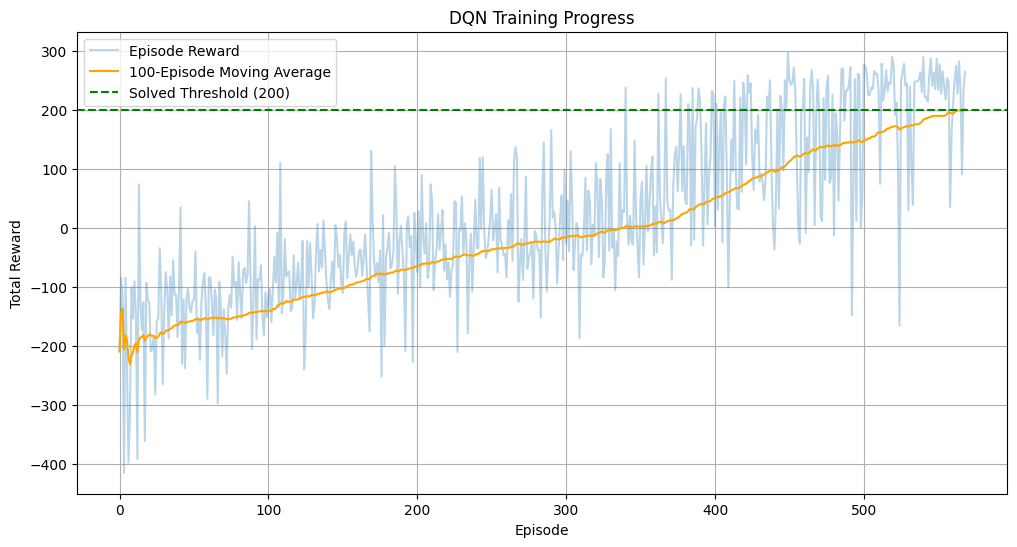

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 📊 Plot Rewards + Moving Average
def plot_training_curve(rewards, threshold=200):
    plt.figure(figsize=(12, 6))

    # Plot the rewards per episode
    plt.plot(rewards, label="Episode Reward", alpha=0.3)

    # Plot the 100-episode moving average
    plt.plot(
        [np.mean(rewards[max(0, i-99):i+1]) for i in range(len(rewards))],
        label='100-Episode Moving Average', color='orange'
    )

    # Add horizontal line for threshold (200)
    plt.axhline(threshold, linestyle="--", color="green", label="Solved Threshold (200)")

    # Set the labels and title
    plt.xlabel('Episode')
    plt.ylabel('Total Reward')
    plt.title("DQN Training Progress")


    # Add legend and grid
    plt.legend()
    plt.grid(True)

    # Show the plot
    plt.show()

# Call the function with the rewards variable
plot_training_curve(rewards)


## Recording an Episode of the Trained Agent

In [ ]:
import gymnasium as gym
from gymnasium.wrappers import RecordVideo
import os
from IPython.display import Video

def watch_landing(q_net, env_name="LunarLander-v3", video_folder="dqn_recording", seed=42, epsilon_eval=0.05):
    os.makedirs(video_folder, exist_ok=True)

    env = gym.make(env_name, render_mode="rgb_array")
    env = RecordVideo(env, video_folder=video_folder, episode_trigger=lambda e: True)

    state, _ = env.reset(seed=seed)
    q_net.eval().to(device)
    done = False

    while not done:
        # Use epsilon-greedy during evaluation, with a small epsilon
        action = select_action(q_net, state, epsilon=epsilon_eval, action_dim=env.action_space.n)
        state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

    env.close()
    print(f"Video saved to: {os.path.abspath(video_folder)}")


# Un-comment to record:
watch_landing(q_net)

Video("dqn_recording/rl-video-episode-0.mp4", embed=True)

/usr/local/lib/python3.11/dist-packages/gymnasium/wrappers/rendering.py:296: UserWarning: WARN: Overwriting existing videos at /content/dqn_recording folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Video saved to: /content/dqn_recording


In [ ]:
def watch_landing(q_net, env_name="LunarLander-v3", video_folder="dqn_recording"):
    os.makedirs(video_folder, exist_ok=True)

    env = gym.make(env_name, render_mode="rgb_array")
    env = RecordVideo(
        env,
        video_folder=video_folder,
        episode_trigger=lambda episode_id: True
    )

    state, _ = env.reset()
    done = False
    total_reward = 0

    while not done:
        action = select_action(q_net, state, epsilon=0.0, action_dim=env.action_space.n)
        state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        total_reward += reward

    env.close()
    print(f"Video saved to: {os.path.abspath(video_folder)}")

# Un-comment to record:
watch_landing(q_net)
Video("dqn_recording/rl-video-episode-0.mp4", embed=True)

Video saved to: /content/dqn_recording


## Summary of Final Results


In [ ]:
# Summary Report
def summarize_results(rewards, window=100):
    last_rewards = rewards[-window:]
    avg_reward = np.mean(last_rewards)
    std_reward = np.std(last_rewards)

    print(f"Last {window} Episodes - Average Reward: {avg_reward:.2f} | Std Dev: {std_reward:.2f}")

    if avg_reward >= 200:
        print("Agent has converged (avg ≥ 200)!")
    else:
        print("Agent has not converged (avg < 200)!")

    return avg_reward, std_reward

avg_reward, std_reward = summarize_results(rewards)

Last 100 Episodes - Average Reward: 200.68 | Std Dev: 94.28
Agent has converged (avg ≥ 200)!


# Actor-Critic (AC) Implementation for LunarLander-v3


## Actor Network

The **Actor** is a neural network that learns a **policy** $\pi(a|s)$, represented as a **probability distribution** over actions given a state.

### Architecture:
- Input: state vector of dimension `state_dim`
- Two hidden layers with ReLU activation
- Output layer with `action_dim` units followed by a **Softmax** to output action probabilities

### Output:
The output is a vector of probabilities for each discrete action, used to sample actions during training or evaluation.


## Critic Network

The **Critic** is a neural network that estimates the **state-value function** $V(s)$, which predicts the expected return from a given state under the current policy.

### Architecture:
- Input: state vector of dimension `state_dim`
- Two hidden layers with ReLU activation
- Output: a single scalar representing the estimated value $V(s)$

### Purpose:
The Critic provides feedback to the Actor by evaluating how good the selected actions are, allowing the Actor to update its policy using the **advantage**:
$$
A(s, a) = r + \gamma V(s') - V(s)
$$


## Action Selection for Actor-Critic

This function selects an action using the **Actor network**, which outputs a probability distribution over actions.

### Steps:
1. Convert the input `state` to a PyTorch tensor and move it to the appropriate device.
2. Use the **Actor** network to compute action probabilities: $\pi(a|s)$.
3. Create a `Categorical` distribution from the probabilities.
4. Sample an action from this distribution.
5. Return both the sampled action and its **log probability**.

The log probability is used later in the Actor's loss function to compute the policy gradient:
$$
\text{loss}_{\text{actor}} = -\log \pi(a|s) \cdot \text{advantage}
$$


## Actor-Critic Training Step

This function performs a single optimization step for both the **Actor** and **Critic** networks based on a sampled batch of experience.

---

### Overview

The Actor-Critic algorithm combines **value-based** and **policy-based** learning:

- The **Critic** estimates the value function $V(s)$ and helps evaluate the quality of actions.
- The **Actor** updates the policy $\pi(a|s)$ using the advantage estimated by the Critic.

---

### 1. Sample Transitions

We draw a random batch of transitions $\{(s, a, r, s', d)\}$ from the replay buffer to break temporal correlations.

---

### 2. Reward Normalization

We normalize the rewards:
$$
r \leftarrow \frac{r - \bar{r}}{\sigma_r + \varepsilon}
$$
This helps stabilize learning, especially when reward scales vary.

---

### 3. Critic Update

The Critic is trained to minimize the Mean Squared Error between its prediction and a target:
$$
\text{Target:} \quad y = r + \gamma \cdot V(s') \cdot (1 - d) \\
\text{Loss:} \quad \mathcal{L}_{\text{critic}} = \left(y - V(s)\right)^2
$$

---

### 4. Actor Update

The Actor is updated to maximize expected advantage:
$$
\text{Advantage:} \quad A(s, a) = y - V(s) \\
\text{Loss:} \quad \mathcal{L}_{\text{actor}} = -\log \pi(a|s) \cdot A(s, a)
$$

We use a categorical distribution over actions and clip the advantage to limit large gradient updates.

---


## Training Loop for Actor-Critic Agent

This function implements the **training process** of the Actor-Critic algorithm using a replay buffer. It orchestrates the interaction with the environment, stores experiences, and triggers optimization steps for the Actor and Critic.

---

###  Episode Loop

We run the training for a fixed number of episodes (default: 1000). For each episode:

1. **Initialize** the environment and set the starting state.
2. Run the episode until `done` is True (either `terminated` or `truncated`).

---

###  Interaction with Environment

At each step within the episode:

- Select an action from the Actor's policy distribution:
  $$
  a \sim \pi(a|s)
  $$
- Step the environment with that action and collect the next state and reward.
- Store the transition tuple $(s, a, r, s', d)$ in the replay buffer.

---

###  Learning Step

After storing the transition, the agent updates both the Actor and Critic using:
```python
train_ac(...)


## Training the Actor-Critic Agent

We now initialize the LunarLander environment, define the Actor and Critic neural networks, and set up the Replay Buffer. Once everything is in place, we begin training the agent over multiple episodes using the Actor-Critic algorithm.


## Moving Average Utility

This helper function computes the moving average of episode rewards. It helps smooth out short-term fluctuations and visualize long-term learning trends during training.


## Random Recording an Episode of the Trained Agent

## Summary of Final Results


NEW

In [4]:
import gymnasium as gym
from gymnasium.wrappers import RecordVideo
import os
import torch
from IPython.display import Video
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import random
from typing import Tuple
# Reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = torch.cuda.is_available()

# Environment
env = gym.make("LunarLander-v3")
env.reset(seed=SEED)
env.action_space.seed(SEED)
env.observation_space.seed(SEED)

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

# Hyperparameters
GAMMA = 0.99
ENTROPY_COEF_INIT = 0.02
ENTROPY_COEF_MIN = 0.003
ENTROPY_DECAY = 0.999
ACTOR_LR = 1e-3
CRITIC_LR = 2e-3
VALUE_LOSS_COEF = 0.5
MAX_GRAD_NORM = 0.5
CRITIC_UPDATES_PER_EP = 2

# Networks
class Actor(nn.Module):
    def __init__(self, s, a):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(s, 512), nn.ReLU(),
            nn.Linear(512, 512), nn.ReLU(),
            nn.Linear(512, a)
        )
    def forward(self, x): return self.net(x)

class Critic(nn.Module):
    def __init__(self, s):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(s, 512), nn.ReLU(),
            nn.Linear(512, 512), nn.ReLU(),
            nn.Linear(512, 1)
        )
    def forward(self, x): return self.net(x).squeeze(-1)

actor = Actor(state_dim, action_dim).to(device)
critic = Critic(state_dim).to(device)
actor_opt = optim.Adam(actor.parameters(), lr=ACTOR_LR)
critic_opt = optim.Adam(critic.parameters(), lr=CRITIC_LR)

@torch.no_grad()
def sample_action(state_np: np.ndarray):
    s = torch.tensor(state_np, dtype=torch.float32, device=device).unsqueeze(0)
    dist = torch.distributions.Categorical(logits=actor(s))
    a = dist.sample()
    return a.item(), s.squeeze(0)

entropy_coef = ENTROPY_COEF_INIT

def rollout_and_update(ep: int) -> Tuple[float, float, float]:
    global entropy_coef
    state, _ = env.reset()
    state = np.asarray(state, dtype=np.float32)

    S, A, R, V = [], [], [], []
    done, ep_ret = False, 0.0

    while not done:
        a, s_t = sample_action(state)
        v_t = critic(s_t.unsqueeze(0)).squeeze(0)

        nxt, r, term, trunc, _ = env.step(a)
        done = term or trunc
        nxt = np.asarray(nxt, dtype=np.float32)

        S.append(s_t)
        A.append(a)
        R.append(torch.tensor(r, dtype=torch.float32, device=device))
        V.append(v_t)

        state = nxt
        ep_ret += r

    with torch.no_grad():
        if done:
            boot = torch.tensor(0.0, dtype=torch.float32, device=device)
        else:
            boot = critic(torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)).squeeze(0)

    S = torch.stack(S)
    A = torch.tensor(A, dtype=torch.int64, device=device)
    R = torch.stack(R)
    V = torch.stack(V)
    V = torch.cat([V, boot.unsqueeze(0)])

    logits = actor(S)
    dist = torch.distributions.Categorical(logits=logits)
    logp = dist.log_prob(A)
    ent = dist.entropy()

    # Monte Carlo returns
    returns = torch.zeros_like(R)
    G = boot
    for t in reversed(range(len(R))):
        G = R[t] + GAMMA * G
        returns[t] = G

    adv = returns - V[:-1]
    adv = (adv - adv.mean()) / (adv.std() + 1e-8)

    # Actor update
    actor_loss = -(logp * adv.detach()).mean() - entropy_coef * ent.mean()
    actor_opt.zero_grad()
    actor_loss.backward()
    nn.utils.clip_grad_norm_(actor.parameters(), MAX_GRAD_NORM)
    actor_opt.step()

    # Critic update(s)
    for _ in range(CRITIC_UPDATES_PER_EP):
        value_preds = critic(S)
        critic_loss = VALUE_LOSS_COEF * nn.MSELoss()(value_preds, returns.detach())
        critic_opt.zero_grad()
        critic_loss.backward()
        nn.utils.clip_grad_norm_(critic.parameters(), MAX_GRAD_NORM)
        critic_opt.step()

    # Entropy decay with floor
    entropy_coef = max(entropy_coef * ENTROPY_DECAY, ENTROPY_COEF_MIN)

    return ep_ret, actor_loss.item(), critic_loss.item()

def train_ac_agent(num_episodes: int = 3000, solve_score: float = 200.0):
    rewards_hist, avg_rewards_hist = [], []
    actor_loss_hist, critic_loss_hist = [], []
    convergence_ep = None
    patience = 10
    stable_count = 0

    for ep in range(num_episodes):
        reward, a_loss, c_loss = rollout_and_update(ep)
        rewards_hist.append(reward)
        actor_loss_hist.append(a_loss)
        critic_loss_hist.append(c_loss)

        avg = np.mean(rewards_hist[-100:]) if len(rewards_hist) >= 100 else np.mean(rewards_hist)
        avg_rewards_hist.append(avg)

        if avg >= solve_score:
            stable_count += 1
        else:
            stable_count = 0

        if convergence_ep is None and stable_count >= patience:
            convergence_ep = ep + 1
            print(f"\n Environment solved at episode {convergence_ep} with avg reward {avg:.2f}")
            break

        if (ep + 1) % 100 == 0:
            print(f"Episode {ep + 1:4d} | Avg Reward (100): {avg:7.2f} | "
                  f"Entropy Coef: {entropy_coef:.4f} | "
                  f"Actor Loss: {a_loss:.4f} | Critic Loss: {c_loss:.4f}")

    return rewards_hist, avg_rewards_hist, actor_loss_hist, critic_loss_hist, convergence_ep

# Train the agent
rewards, avg_rewards, a_losses, c_losses, solved_at = train_ac_agent()


Episode  100 | Avg Reward (100): -162.54 | Entropy Coef: 0.0181 | Actor Loss: 0.1072 | Critic Loss: 1290.3444
Episode  200 | Avg Reward (100):  -72.76 | Entropy Coef: 0.0164 | Actor Loss: -0.0632 | Critic Loss: 125.3684
Episode  300 | Avg Reward (100):   -2.44 | Entropy Coef: 0.0148 | Actor Loss: 0.0215 | Critic Loss: 109.1076
Episode  400 | Avg Reward (100):   14.88 | Entropy Coef: 0.0134 | Actor Loss: -0.0566 | Critic Loss: 85.2071
Episode  500 | Avg Reward (100):  119.74 | Entropy Coef: 0.0121 | Actor Loss: -0.0722 | Critic Loss: 3128.0457
Episode  600 | Avg Reward (100):    7.08 | Entropy Coef: 0.0110 | Actor Loss: -0.1652 | Critic Loss: 690.7690
Episode  700 | Avg Reward (100):   92.62 | Entropy Coef: 0.0099 | Actor Loss: 0.1199 | Critic Loss: 608.8887
Episode  800 | Avg Reward (100):   97.84 | Entropy Coef: 0.0090 | Actor Loss: 0.0625 | Critic Loss: 1367.2579
Episode  900 | Avg Reward (100):   -0.17 | Entropy Coef: 0.0081 | Actor Loss: 0.1443 | Critic Loss: 559.8345
Episode 1000 

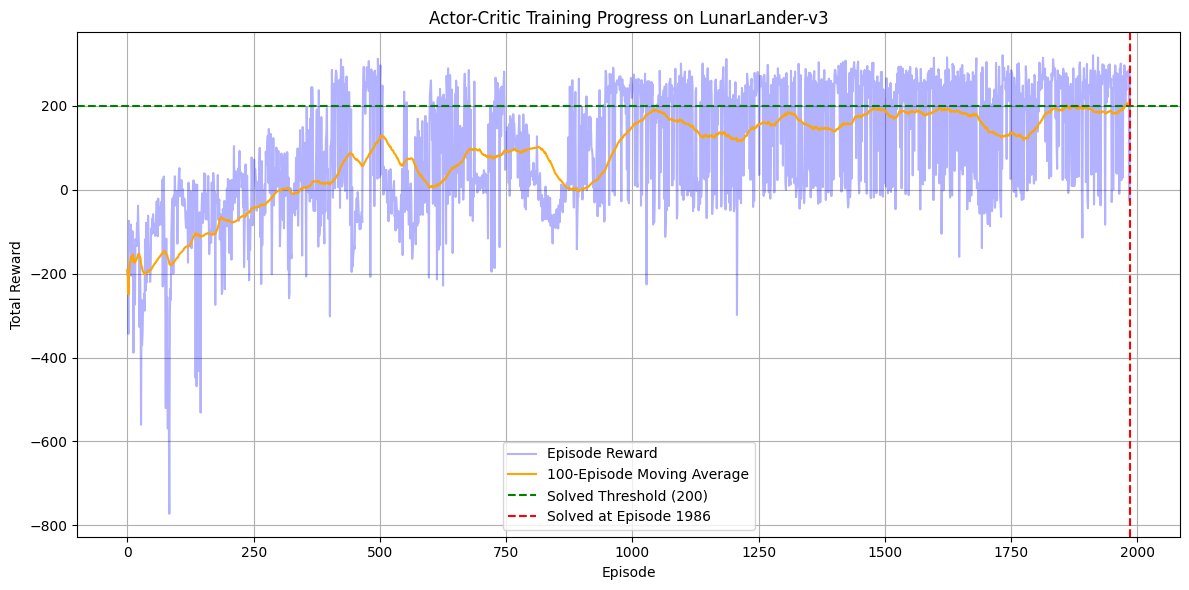

In [5]:
import matplotlib.pyplot as plt
import numpy as np

#  Plot Rewards + Moving Average (AC Version)
def plot_training_curve(rewards, avg_rewards, solved_at=None, threshold=200):
    plt.figure(figsize=(12, 6))

    # Raw per-episode rewards
    plt.plot(rewards, label="Episode Reward", alpha=0.3, color="blue")

    # 100-episode moving average (already computed during training)
    plt.plot(avg_rewards, label="100-Episode Moving Average", color="orange")

    # Solved threshold line
    plt.axhline(threshold, linestyle="--", color="green", label="Solved Threshold (200)")

    # Solved marker (if exists)
    if solved_at:
        plt.axvline(solved_at, linestyle="--", color="red", label=f"Solved at Episode {solved_at}")

    # Labels and formatting
    plt.xlabel("Episode")
    plt.ylabel("Total Reward")
    plt.title("Actor-Critic Training Progress on LunarLander-v3")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Call the plot function after training
plot_training_curve(rewards, avg_rewards, solved_at)


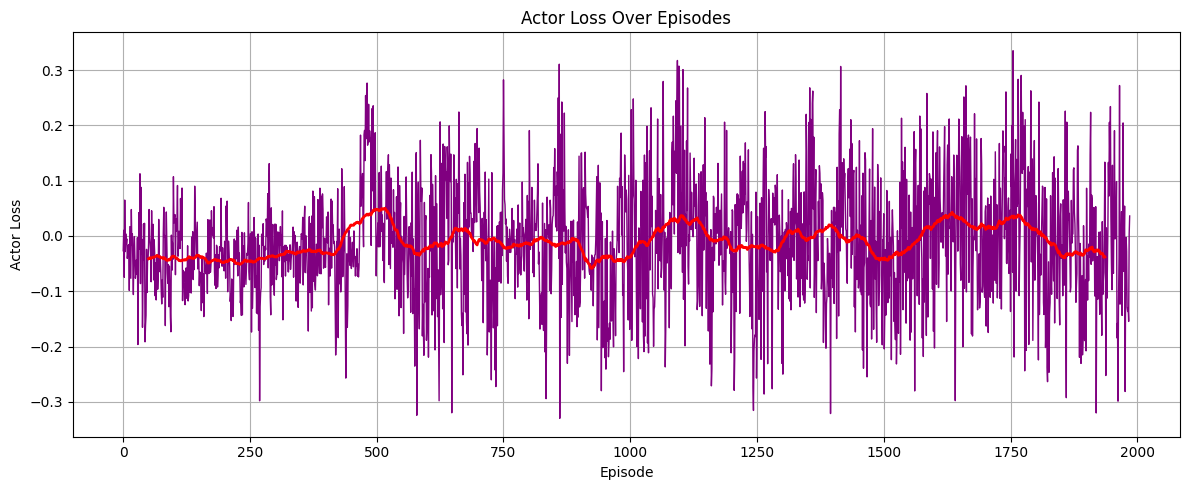

In [8]:
import matplotlib.pyplot as plt
# ── handy centred moving-average utility ──────────────────────────────────
def moving_average(arr, window):
    if len(arr) < window:
        return arr                         # not enough points to smooth
    filt = np.ones(window) / window
    return np.convolve(arr, filt, mode="valid")

def plot_actor_loss(a_losses,window):
    plt.figure(figsize=(12, 5))
    plt.plot(a_losses, color="purple", linewidth=1)
    plt.title("Actor Loss Over Episodes")
    plt.xlabel("Episode")
    plt.ylabel("Actor Loss")

    if len(a_losses) >= window:
        smoothed = moving_average(a_losses, window)
        x = np.arange(len(smoothed)) + (window // 2)
        plt.plot(x, smoothed,
                 label=f"Actor Loss ({window}-ep MA)",
                 linewidth=2,
                 color="red")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Call the plot function
plot_actor_loss(a_losses,100)


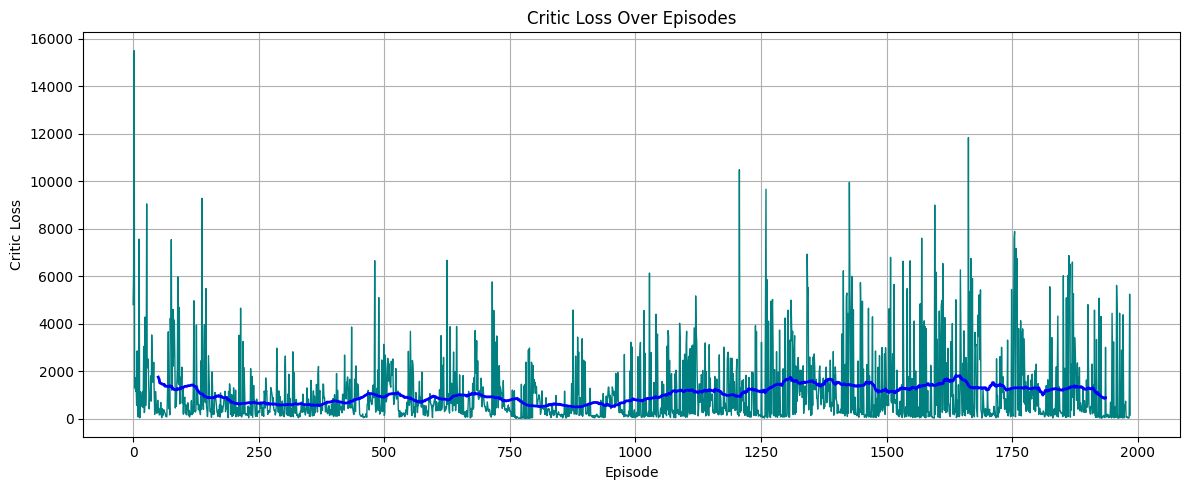

In [12]:
def plot_critic_loss(c_losses,window):
    plt.figure(figsize=(12, 5))
    plt.plot(c_losses, color="teal", linewidth=1)
    plt.title("Critic Loss Over Episodes")
    plt.xlabel("Episode")
    plt.ylabel("Critic Loss")
    if len(c_losses) >= window:
        smoothed = moving_average(c_losses, window)
        x = np.arange(len(smoothed)) + (window // 2)
        plt.plot(x, smoothed,
                 label=f"Critic Loss ({window}-ep MA)",
                 linewidth=2,
                 color="blue")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Call the plot function
plot_critic_loss(c_losses,100)


In [13]:
import gymnasium as gym
from gymnasium.wrappers import RecordVideo
import os
import torch
from IPython.display import Video

def watch_landing_ac(actor, env_name="LunarLander-v3", video_folder="ac_recording", seed=42):
    os.makedirs(video_folder, exist_ok=True)

    env = gym.make(env_name, render_mode="rgb_array")
    env = RecordVideo(env, video_folder=video_folder, episode_trigger=lambda e: True)
    state, _ = env.reset(seed=seed)

    done = False
    total_reward = 0.0
    actor.eval()

    with torch.no_grad():
        while not done:
            state_tensor = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
            logits = actor(state_tensor)
            dist = torch.distributions.Categorical(logits=logits)
            action = dist.sample().item()

            state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            total_reward += reward

    env.close()

# Record a video of the trained actor
watch_landing_ac(actor)

#  Inline video playback (make sure the video is actually created)
Video("ac_recording/rl-video-episode-0.mp4", embed=True)


/usr/local/lib/python3.11/dist-packages/gymnasium/wrappers/rendering.py:296: UserWarning: WARN: Overwriting existing videos at /content/ac_recording folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(
